# SIFT scaling experiment: cost of reaching recall@10 = 0.95

This experiment measures how the cost of reaching **recall@10 = 0.95** changes as the SIFT database grows from **100K to 300K to 1M vectors** for:

- **Exact search** (`IndexFlatL2`), the quality and latency reference.
- **HNSW**, with a fixed graph construction policy and an `efSearch` sweep.
- **IVF-Flat**, with a scale-aware `nlist` and an `nprobe` sweep.

The comparison is made at the fastest measured operating point whose recall is at least 0.95. All methods use the same 10,000 queries, `k=10`, one query per `search()` call, one FAISS thread for timing, and three timing repeats reported as the median. Build time and serialized index size are retained because scaling cost is not only query latency.


## Hypothesis (short, committed to git)

The hypothesis is in **`hypothesis_part3.md`**, committed separately from this notebook:

> Exact search has to look at every vector, so its cost grows in step with N. IVF-Flat still scans a fixed share of the vectors, so it grows almost as fast, from a lower start. HNSW only follows a short path through a graph, so its cost grows slowest. The advantage over exact search should therefore grow with N, most of all for HNSW.

Four numbered predictions with ratios are in the file and are checked automatically at the end. The cell below shows the git status. **If it warns, report that the hypothesis was not committed before the first run** (an earlier run of this notebook already existed when the file was written).


In [1]:

"""
This cell checks the git status of hypothesis_part3.md (exists, tracked, unchanged) and whether results from an earlier run already exist. It prints a warning, not an error, because a warning means the hypothesis was not pre-registered and the report must say so.
"""
import datetime, glob, os, subprocess

HYP_FILE = "hypothesis_part3.md"

def _git(*args):
    try:
        r = subprocess.run(["git", *args], capture_output=True, text=True, timeout=30)
        return r.returncode, r.stdout.strip()
    except Exception as e:
        return 1, str(e)

problems = []
rc, _ = _git("rev-parse", "--is-inside-work-tree")
if rc != 0:
    problems.append("this directory is not a git repository")
elif not os.path.exists(HYP_FILE):
    problems.append(f"{HYP_FILE} does not exist")
else:
    if _git("ls-files", "--error-unmatch", HYP_FILE)[0] != 0:
        problems.append(f"{HYP_FILE} is not tracked: git add {HYP_FILE} && git commit")
    if _git("status", "--porcelain", "--", HYP_FILE)[1]:
        problems.append(f"{HYP_FILE} has uncommitted changes")
    print("hypothesis commit:", _git("log", "-1", "--format=%h | %aI | %s", "--", HYP_FILE)[1] or "(none)")
    if glob.glob("./data/processed/results_sift_scaling*.csv"):
        problems.append("results from an earlier run already exist: the hypothesis is not blind to them")
print("this run started :", datetime.datetime.now().astimezone().isoformat(timespec="seconds"))
print("\nWARNING:\n  - " + "\n  - ".join(problems) if problems else "OK: committed, unchanged, first run.")


hypothesis commit: (none)
this run started : 2026-10-29T11:24:50+05:30

  - hypothesis_part3.md is not tracked: git add hypothesis_part3.md && git commit
  - hypothesis_part3.md has uncommitted changes
  - results from an earlier run already exist: the hypothesis is not blind to them


## Experimental decisions and alternatives

**Database sizes.** The first 100K and first 300K vectors of the official SIFT training set are used, plus the complete 1M set. This keeps the data distribution consistent while making the experiment reproducible. A random subset could have been chosen, but then differences between sizes would mix scaling with sampling noise.

**Ground truth.** Exact top-10 neighbours are recomputed independently for each subset. Reusing the 1M ground truth would be incorrect: a neighbour outside a smaller subset cannot be returned by an index built on that subset.

**HNSW.** `M=16` and `efConstruction=100` are held fixed so only database size changes. A different choice such as `M=8` would reduce memory, while `M=32` could improve recall, but either would change the index design rather than isolate scaling. `efSearch` is swept because it is the query-time cost knob.

**IVF-Flat.** `nlist` is set close to `sqrt(N)` (316, 548, and 1000), keeping average list size approximately comparable across scales. A fixed `nlist=1024` could have been used for all sizes, but it would make the 100K case unusually fine and the 1M case unusually coarse. `nprobe` is swept because it controls query work.

**Exact search.** Exact search is measured rather than treated as free. It is the baseline cost at recall 1.0 and shows how the ANN methods scale relative to exhaustive comparison.


## How "cost of reaching recall 0.95" is measured (changes from the first version)

- **Interpolated at exactly 0.95.** The first version took the first sweep point with recall of at least 0.95, which overshot by different amounts (0.950 to 0.966) at different sizes. The cost is now interpolated between the two sweep points around 0.95 (log-linear), so every size is compared at the same recall. The first-point value is still shown for reference.
- **Two cost measures.** *Query time* (single query, single thread, median of 5 repeats) and *distance computations per query* (hardware independent; for IVF-Flat this includes the `nlist` centroid comparisons). Latency differences of a few tenths of a millisecond are within timing noise, so the second measure is the cross-check.
- **Timing noise is reported,** not hidden: the spread between repeats is printed for the selected points.
- **Scaling is summarised by the ratio 1M / 100K and by the slope on log-log axes** (cost proportional to N^slope). With only three sizes the slope is a summary, not proof of a functional form.
- **Speedup over exact search** is exact time divided by index time (larger is better).


In [2]:
import gc
import time

import faiss
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from code.ann_utils import K, MAX_THREADS, exact_dists, time_single_query, index_size_bytes, cost_at_recall

N_TIME_Q = 500
REPS = 5
TARGET_RECALL = 0.95
SEED = 1234
SIZES = (100_000, 300_000, 1_000_000)
EFSEARCH_GRID = [10, 16, 24, 32, 40, 48, 64, 80, 96, 128, 192, 256, 384, 512]
NPROBE_GRID = [1, 2, 4, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512]

with h5py.File('./data/raw/sift-128-euclidean.hdf5', 'r') as f:
    train_all = np.ascontiguousarray(f['train'][:], dtype=np.float32)
    test = np.ascontiguousarray(f['test'][:], dtype=np.float32)


class ScaledSIFT:
    def __init__(self, n):
        self.name = f'sift_{n // 1000}k'
        self.n = n
        self.train = train_all[:n]
        self.test = test
        self.d = self.train.shape[1]
        self.metric = 'l2'
        self.gt_ids = None
        self.gt_d = None

    def recall(self, ids):
        ret = np.asarray(ids)[:, :K]
        ret_d = exact_dists(ret, self.train, self.test, self.metric)
        from code.ann_utils import recall_from_dists
        return recall_from_dists(ret, ret_d, self.gt_d, K)


EVALS = {n: ScaledSIFT(n) for n in SIZES}
RESULTS = []
BUILDS = []
print(f'FAISS {faiss.__version__} | build threads: {MAX_THREADS} | timing threads: 1')
print(f'train shape: {train_all.shape}, test shape: {test.shape}')


FAISS 1.15.1 | build threads: 20 | timing threads: 1
train shape: (1000000, 128), test shape: (10000, 128)


## Exact baseline: one try per scale

The exact index is built separately for each database size. Its recall is 1.0 by construction, and its single-query QPS is the reference against which ANN latency is compared.

In [3]:
BASELINES = {}
for n, ev in EVALS.items():
    exact = faiss.IndexFlatL2(ev.d)
    exact.add(ev.train)
    _, ev.gt_ids = exact.search(ev.test, K)
    ev.gt_d = exact_dists(ev.gt_ids, ev.train, ev.test, ev.metric)
    qps, _, _ = time_single_query(exact, ev.test, K, N_TIME_Q, REPS)
    BASELINES[n] = {'qps': qps, 'ms_per_query': 1e3 / qps}
    RESULTS.append({'index': 'Exact', 'size': n, 'try': 'exact', 'param': 0,
                    'recall': 1.0, 'qps': qps, 'ms_per_query': 1e3 / qps})
    print(f'{ev.name}: recall=1.0000 | {qps:,.1f} QPS | {1e3 / qps:.3f} ms/query')
    del exact
    gc.collect()


sift_100k: recall=1.0000 | 270.8 QPS | 3.693 ms/query
sift_300k: recall=1.0000 | 108.0 QPS | 9.259 ms/query
sift_1000k: recall=1.0000 | 32.9 QPS | 30.394 ms/query


## Try 1: HNSW at 100K

**Decision.** Build HNSW with `M=16`, `efConstruction=100`, then sweep `efSearch`.

**Reasoning.** This is the base HNSW design used in the earlier benchmark. Holding construction parameters fixed makes the result a scaling measurement, while `efSearch` exposes the cheapest point that reaches the target.

**Alternative not chosen.** Re-tuning `M` for 100K might produce a faster index, but it would answer an engineering-tuning question rather than the requested fixed-design scaling question.

In [4]:
def run_hnsw_try(n):
    ev = EVALS[n]
    index = faiss.IndexHNSWFlat(ev.d, 16)
    index.hnsw.efConstruction = 100
    faiss.omp_set_num_threads(MAX_THREADS)
    t0 = time.perf_counter()
    index.add(ev.train)
    build_s = time.perf_counter() - t0
    print(f'[{ev.name}] HNSW build: {build_s:.1f}s')
    rows = []
    for ef in EFSEARCH_GRID:
        index.hnsw.efSearch = ef
        _, ids = index.search(ev.test, K)
        recall = ev.recall(ids)
        qps, qps_reps, extra = time_single_query(index, ev.test, K, N_TIME_Q, REPS, collect_stats='hnsw')
        row = {'index': 'HNSW', 'size': n, 'try': 'M16_efC100', 'param': ef,
               'recall': recall, 'qps': qps, 'ms_per_query': 1e3 / qps,
               'qps_min': min(qps_reps), 'qps_max': max(qps_reps), **extra}
        rows.append(row)
        print(f'  efSearch={ef:<4} recall={recall:.4f} | {qps:,.1f} QPS')
        if recall >= 0.99:
            break
    size_mb = index_size_bytes(index) / 1e6
    BUILDS.append({'index': 'HNSW', 'size': n, 'try': 'M16_efC100',
                    'build_s': build_s, 'size_mb': size_mb,
                    'bytes_per_vector': size_mb * 1e6 / n})
    RESULTS.extend(rows)
    del index
    gc.collect()

run_hnsw_try(100_000)


[sift_100k] HNSW build: 1.4s
  efSearch=10   recall=0.7795 | 42,111.6 QPS
  efSearch=16   recall=0.8601 | 29,762.4 QPS
  efSearch=24   recall=0.9153 | 22,052.0 QPS
  efSearch=32   recall=0.9457 | 17,209.5 QPS
  efSearch=40   recall=0.9625 | 15,510.2 QPS
  efSearch=48   recall=0.9734 | 12,453.1 QPS
  efSearch=64   recall=0.9845 | 9,986.6 QPS
  efSearch=80   recall=0.9903 | 7,921.8 QPS


## Try 2: HNSW at 300K

**Decision.** Repeat exactly the 100K HNSW protocol at 300K.

**Reasoning.** The same `M`, `efConstruction`, timing protocol, and search grid make changes in build time, memory, and target latency attributable to the larger database.

**Alternative not chosen.** Increasing `efConstruction` at 300K could improve graph quality, but it would add a second changing variable and make the scaling curve ambiguous.

In [5]:
run_hnsw_try(300_000)

[sift_300k] HNSW build: 6.9s
  efSearch=10   recall=0.7364 | 27,471.9 QPS
  efSearch=16   recall=0.8266 | 20,758.3 QPS
  efSearch=24   recall=0.8875 | 18,217.1 QPS
  efSearch=32   recall=0.9215 | 14,100.1 QPS
  efSearch=40   recall=0.9435 | 12,113.3 QPS
  efSearch=48   recall=0.9578 | 10,504.3 QPS
  efSearch=64   recall=0.9735 | 8,093.4 QPS
  efSearch=80   recall=0.9826 | 6,715.1 QPS
  efSearch=96   recall=0.9878 | 5,827.1 QPS
  efSearch=128  recall=0.9930 | 4,440.0 QPS


## Try 3: HNSW at 1M

**Decision.** Repeat the fixed HNSW protocol on the complete SIFT training set.

**Reasoning.** This is the requested large-scale endpoint and is directly comparable with the existing 1M HNSW benchmark.

**Alternative not chosen.** A wider `efSearch` grid above 512 was not added because the target is 0.95, not 0.99; the sweep stops once the measured target is reached (or at 0.99).

In [6]:
run_hnsw_try(1_000_000)

[sift_1000k] HNSW build: 29.5s
  efSearch=10   recall=0.7003 | 21,919.7 QPS
  efSearch=16   recall=0.7910 | 18,340.7 QPS
  efSearch=24   recall=0.8566 | 13,345.1 QPS
  efSearch=32   recall=0.8946 | 12,585.8 QPS
  efSearch=40   recall=0.9197 | 10,543.9 QPS
  efSearch=48   recall=0.9354 | 9,212.5 QPS
  efSearch=64   recall=0.9568 | 7,061.4 QPS
  efSearch=80   recall=0.9692 | 5,568.2 QPS
  efSearch=96   recall=0.9766 | 4,462.1 QPS
  efSearch=128  recall=0.9854 | 3,258.9 QPS
  efSearch=192  recall=0.9930 | 2,449.6 QPS


## Try 4: IVF-Flat at 100K

**Decision.** Use `nlist=316`, approximately `sqrt(100K)`, and sweep `nprobe`.

**Reasoning.** Keeping the average list size near `sqrt(N)` preserves the balance between centroid work and list scanning as the database grows.

**Alternative not chosen.** A fixed `nlist=1024` would make this small database unusually fragmented and would not be a fair scale-aware comparison.

In [7]:
def run_ivf_try(n):
    ev = EVALS[n]
    nlist = int(round(np.sqrt(n)))
    quantizer = faiss.IndexFlatL2(ev.d)
    index = faiss.IndexIVFFlat(quantizer, ev.d, nlist, faiss.METRIC_L2)
    index.cp.niter, index.cp.seed = 25, SEED
    faiss.omp_set_num_threads(MAX_THREADS)
    t0 = time.perf_counter()
    index.train(ev.train)
    train_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    index.add(ev.train)
    add_s = time.perf_counter() - t0
    print(f'[{ev.name}] IVF-Flat nlist={nlist}: train={train_s:.1f}s, add={add_s:.1f}s')
    rows = []
    for nprobe in dict.fromkeys(min(v, nlist) for v in NPROBE_GRID):
        index.nprobe = nprobe
        _, ids = index.search(ev.test, K)
        recall = ev.recall(ids)
        qps, qps_reps, extra = time_single_query(index, ev.test, K, N_TIME_Q, REPS, collect_stats='ivf')
        row = {'index': 'IVF-Flat', 'size': n, 'try': f'nlist{nlist}', 'param': nprobe,
               'recall': recall, 'qps': qps, 'ms_per_query': 1e3 / qps,
               'qps_min': min(qps_reps), 'qps_max': max(qps_reps), **extra}
        rows.append(row)
        print(f'  nprobe={nprobe:<4} recall={recall:.4f} | {qps:,.1f} QPS')
        if recall >= 0.99:
            break
    size_mb = index_size_bytes(index) / 1e6
    BUILDS.append({'index': 'IVF-Flat', 'size': n, 'try': f'nlist{nlist}',
                'build_s': train_s + add_s, 'train_s': train_s, 'add_s': add_s,
                'size_mb': size_mb, 'bytes_per_vector': size_mb * 1e6 / n})
    RESULTS.extend(rows)
    del index
    gc.collect()

run_ivf_try(100_000)


[sift_100k] IVF-Flat nlist=316: train=1.5s, add=0.1s
  nprobe=1    recall=0.4062 | 57,374.3 QPS
  nprobe=2    recall=0.5855 | 37,200.4 QPS
  nprobe=4    recall=0.7566 | 17,778.8 QPS
  nprobe=8    recall=0.8898 | 11,115.9 QPS
  nprobe=12   recall=0.9411 | 7,414.0 QPS
  nprobe=16   recall=0.9661 | 4,850.9 QPS
  nprobe=24   recall=0.9869 | 3,771.8 QPS
  nprobe=32   recall=0.9943 | 2,827.1 QPS


## Try 5: IVF-Flat at 300K

**Decision.** Repeat IVF-Flat with the scale-aware `nlist=round(sqrt(300K))=548`.

**Reasoning.** This preserves approximately the same average number of vectors per inverted list as the 100K and 1M tries.

**Alternative not chosen.** Reusing the 100K trained centroids would make the partition mismatched to the larger data distribution and would conflate poor training with scaling.

In [8]:
run_ivf_try(300_000)

[sift_300k] IVF-Flat nlist=548: train=3.9s, add=0.3s
  nprobe=1    recall=0.3871 | 34,407.5 QPS
  nprobe=2    recall=0.5574 | 20,915.0 QPS
  nprobe=4    recall=0.7291 | 10,707.3 QPS
  nprobe=8    recall=0.8662 | 5,440.4 QPS
  nprobe=12   recall=0.9222 | 3,932.5 QPS
  nprobe=16   recall=0.9503 | 3,200.8 QPS
  nprobe=24   recall=0.9775 | 2,253.7 QPS
  nprobe=32   recall=0.9882 | 1,554.0 QPS
  nprobe=48   recall=0.9964 | 1,013.3 QPS


## Try 6: IVF-Flat at 1M

**Decision.** Repeat IVF-Flat with `nlist=round(sqrt(1M))=1000`.

**Reasoning.** This is close to the `nlist=1024` base used in the earlier 1M benchmark, so the result can be compared with the previous run while following the same scaling rule.

**Alternative not chosen.** `nlist=4096` would reduce list sizes but increase the fixed centroid-comparison cost; it is a useful tuning experiment, not the cleanest scaling baseline.

In [9]:
run_ivf_try(1_000_000)

[sift_1000k] IVF-Flat nlist=1000: train=11.6s, add=1.8s
  nprobe=1    recall=0.3773 | 20,102.0 QPS
  nprobe=2    recall=0.5431 | 10,905.9 QPS
  nprobe=4    recall=0.7055 | 5,699.9 QPS
  nprobe=8    recall=0.8435 | 3,160.3 QPS
  nprobe=12   recall=0.9029 | 2,283.2 QPS
  nprobe=16   recall=0.9344 | 1,820.4 QPS
  nprobe=24   recall=0.9663 | 1,253.9 QPS
  nprobe=32   recall=0.9807 | 811.0 QPS
  nprobe=48   recall=0.9924 | 610.5 QPS



## Results: cost of reaching recall 0.95


In [10]:

"""
This cell computes, for every index and size, the cost at recall 0.95 interpolated at exactly 0.95 (query time and distance computations), the first-sweep-point value for comparison, build time, size and speedup over exact search. Exact search is included with its measured time and N distance computations.
"""
results_df = pd.DataFrame(RESULTS)
builds_df = pd.DataFrame(BUILDS)
rows = []
for (index, n), g in results_df[results_df["index"] != "Exact"].groupby(["index", "size"], sort=True):
    g = g.copy()
    nlist = int(round(np.sqrt(n)))
    g["work"] = g["dist_comps_per_query"] + (nlist if index == "IVF-Flat" else 0)
    c = cost_at_recall(g, TARGET_RECALL, ["param", "ms_per_query", "work"])
    elig = g[g.recall >= TARGET_RECALL]
    first = elig.loc[elig.qps.idxmax()] if len(elig) else None
    b = builds_df[(builds_df["index"] == index) & (builds_df["size"] == n)].iloc[0]
    rows.append({"index": index, "size": n, "reached": c is not None,
                 "param95": c["param"] if c else np.nan, "ms95": c["ms_per_query"] if c else np.nan,
                 "work95": c["work"] if c else np.nan,
                 "first_ms": first["ms_per_query"] if first is not None else np.nan,
                 "first_recall": first["recall"] if first is not None else np.nan,
                 "floor_limited": c["floor_limited"] if c else False,
                 "build_s": b["build_s"], "size_mb": b["size_mb"], "bytes_per_vector": b["bytes_per_vector"]})
for n in SIZES:
    rows.append({"index": "Exact", "size": n, "reached": True, "param95": np.nan,
                 "ms95": BASELINES[n]["ms_per_query"], "work95": float(n),
                 "first_ms": BASELINES[n]["ms_per_query"], "first_recall": 1.0, "floor_limited": False,
                 "build_s": np.nan, "size_mb": 4 * 128 * n / 1e6, "bytes_per_vector": 512.0})
cost_df = pd.DataFrame(rows).sort_values(["index", "size"]).reset_index(drop=True)
cost_df["exact_ms"] = cost_df["size"].map({n: BASELINES[n]["ms_per_query"] for n in SIZES})
cost_df["speedup_vs_exact"] = cost_df["exact_ms"] / cost_df["ms95"]      # larger = faster than exact search
cost_df["qps95"] = 1e3 / cost_df["ms95"]

pd.set_option("display.width", 200)
print("Cost of reaching recall 0.95 (interpolated at exactly 0.95)")
print(cost_df[["index", "size", "param95", "ms95", "qps95", "work95", "speedup_vs_exact",
               "build_s", "size_mb", "bytes_per_vector"]].round(3).to_string(index=False))
print("\nFor reference, the first sweep point at or above 0.95 (the first version of this analysis):")
print(cost_df[cost_df["index"] != "Exact"][["index", "size", "first_recall", "first_ms"]].round(4).to_string(index=False))
if cost_df["floor_limited"].any():
    print("\nNote: floor_limited rows reach 0.95 already at the weakest setting, so their cost is an upper bound.")


Cost of reaching recall 0.95 (interpolated at exactly 0.95)
   index    size  param95   ms95     qps95      work95  speedup_vs_exact  build_s  size_mb  bytes_per_vector
   Exact  100000      NaN  3.693   270.780  100000.000             1.000      NaN   51.200           512.000
   Exact  300000      NaN  9.259   108.003  300000.000             1.000      NaN  153.600           512.000
   Exact 1000000      NaN 30.394    32.901 1000000.000             1.000      NaN  512.000           512.000
    HNSW  100000   33.885  0.060 16756.521     614.691            61.883    1.447   65.633           656.333
    HNSW  300000   43.459  0.088 11352.870     815.563           105.117    6.889  196.884           656.280
    HNSW 1000000   58.400  0.130  7685.103    1158.855           233.580   29.519  656.258           656.258
IVF-Flat  100000   13.296  0.157  6373.373    4937.334            23.537    1.609   52.164           521.645
IVF-Flat  300000   15.948  0.312  3208.336    9831.631            29

In [11]:

"""
This cell reports timing noise: for each sweep point the spread between the timing repeats, and the number of times QPS rises when the search parameter increases (which should not happen). Large spreads mean the latency comparison should lean on the distance computations instead.
"""
ann = results_df[results_df["index"] != "Exact"].copy()
ann["spread"] = (ann["qps_max"] - ann["qps_min"]) / ann["qps"]
print("relative spread between repeats (max-min)/median, over all sweep points:")
print(ann.groupby(["index", "size"])["spread"].agg(["median", "max"]).round(3).to_string())
viol = 0
for _, g in ann.groupby(["index", "size"]):
    g = g.sort_values("param")
    viol += int((g["qps"].diff() > 0).sum())
print(f"\nsweep points where QPS rose although the search effort increased: {viol} of {len(ann)}")


relative spread between repeats (max-min)/median, over all sweep points:
                  median    max
index    size                  
HNSW     100000    0.121  0.409
         300000    0.085  0.259
         1000000   0.074  0.124
IVF-Flat 100000    0.138  0.216
         300000    0.102  0.308
         1000000   0.125  0.252

sweep points where QPS rose although the search effort increased: 0 of 55


In [12]:

"""
This cell summarises the growth with database size: the ratio 1M / 100K and the log-log slope (cost proportional to N^slope) for query time, distance computations and build time of each index.
"""
def growth(col):
    out = []
    for index, g in cost_df.groupby("index"):
        g = g.sort_values("size")
        v = g[col].to_numpy(dtype=float)
        if np.isnan(v).any():
            continue
        slope = np.polyfit(np.log(g["size"]), np.log(v), 1)[0]
        out.append({"index": index, "100K": v[0], "300K": v[1], "1M": v[2], "ratio 1M/100K": v[2] / v[0], "slope": slope})
    return pd.DataFrame(out).round(3)

for col, title in (("ms95", "query time at recall 0.95 (ms)"), ("work95", "distance computations per query at recall 0.95"),
                   ("build_s", "build time (s)"), ("size_mb", "index size (MB)")):
    print(f"\n--- {title} ---")
    print(growth(col).to_string(index=False))



--- query time at recall 0.95 (ms) ---
   index  100K  300K     1M  ratio 1M/100K  slope
   Exact 3.693 9.259 30.394          8.230  0.917
    HNSW 0.060 0.088  0.130          2.180  0.338
IVF-Flat 0.157 0.312  0.659          4.202  0.623

--- distance computations per query at recall 0.95 ---
   index       100K       300K          1M  ratio 1M/100K  slope
   Exact 100000.000 300000.000 1000000.000         10.000  1.000
    HNSW    614.691    815.563    1158.855          1.885  0.276
IVF-Flat   4937.334   9831.631   21984.046          4.453  0.649

--- build time (s) ---
   index  100K  300K     1M  ratio 1M/100K  slope
    HNSW 1.447 6.889 29.519         20.405  1.308
IVF-Flat 1.609 4.284 13.484          8.379  0.924

--- index size (MB) ---
   index   100K    300K      1M  ratio 1M/100K  slope
   Exact 51.200 153.600 512.000         10.000  1.000
    HNSW 65.633 196.884 656.258          9.999  1.000
IVF-Flat 52.164 156.285 520.520          9.978  0.999



## Scaling plot

Four panels, all against the database size on log-log axes: query time at recall 0.95 **including exact search** (the dotted line shows what linear growth from exact search's 100K value would look like), distance computations per query, build time, and the speedup over exact search.


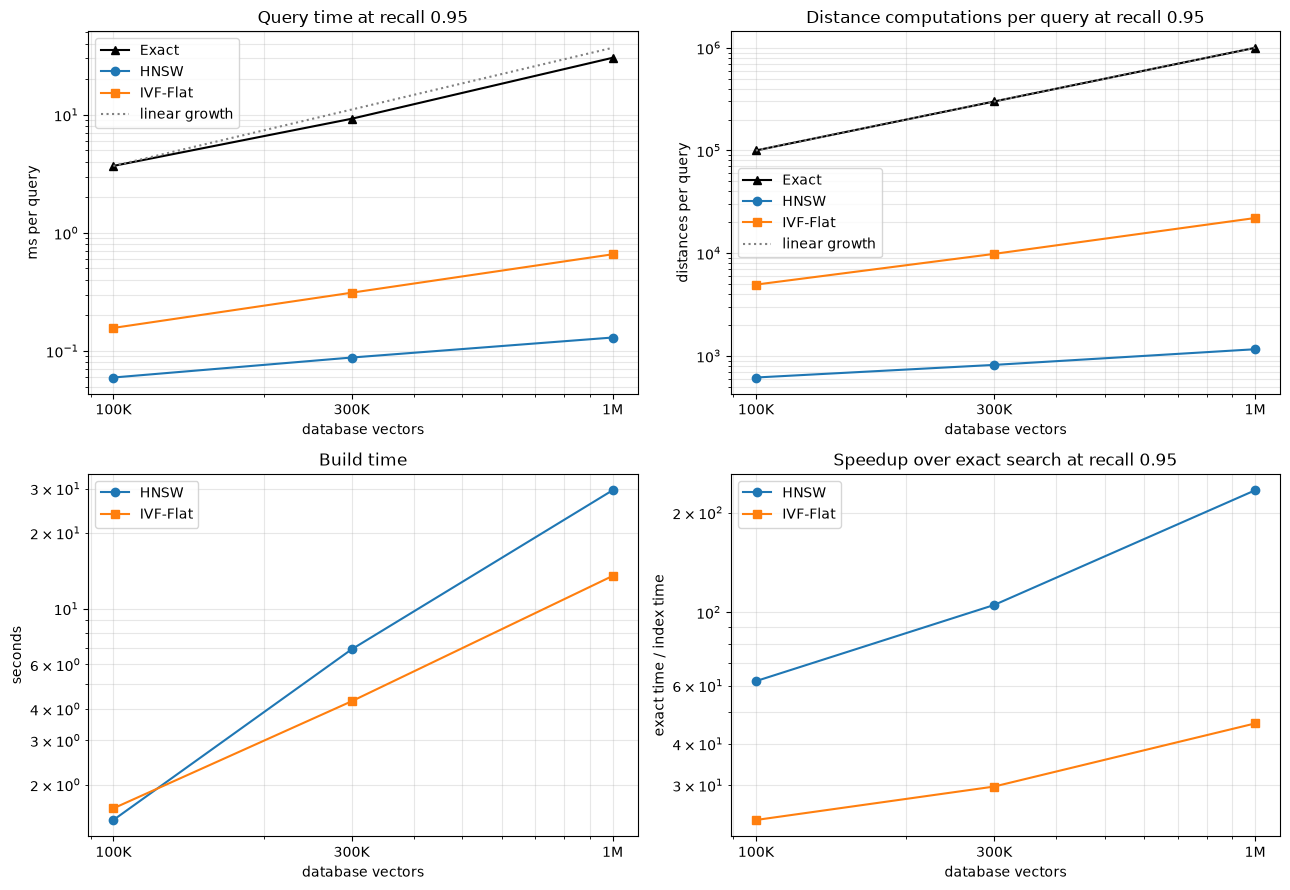

In [13]:

"""
This cell plots the scaling results in four panels (query time including exact search, distance computations, build time, speedup over exact search) and saves the figure to data/processed/plots/sift_scaling_at_095.png.
"""
os_ = __import__("os"); os_.makedirs("./data/processed/plots", exist_ok=True)
sty = {"Exact": ("k", "^"), "HNSW": ("tab:blue", "o"), "IVF-Flat": ("tab:orange", "s")}
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ns = np.array(SIZES, dtype=float)
ex = cost_df[cost_df["index"] == "Exact"].sort_values("size")
for index, g in cost_df.groupby("index"):
    g = g.sort_values("size"); c, mk = sty[index]
    ax[0, 0].plot(g["size"], g["ms95"], mk + "-", color=c, label=index)
    ax[0, 1].plot(g["size"], g["work95"], mk + "-", color=c, label=index)
    if index != "Exact":
        ax[1, 0].plot(g["size"], g["build_s"], mk + "-", color=c, label=index)
        ax[1, 1].plot(g["size"], g["speedup_vs_exact"], mk + "-", color=c, label=index)
ax[0, 0].plot(ns, ex["ms95"].iloc[0] * ns / ns[0], ":", color="grey", label="linear growth")
ax[0, 1].plot(ns, ns, ":", color="grey", label="linear growth")
titles = ["Query time at recall 0.95", "Distance computations per query at recall 0.95",
          "Build time", "Speedup over exact search at recall 0.95"]
ylabels = ["ms per query", "distances per query", "seconds", "exact time / index time"]
for a, t, yl in zip(ax.ravel(), titles, ylabels):
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("database vectors"); a.set_ylabel(yl)
    a.set_xticks(SIZES); a.set_xticklabels(["100K", "300K", "1M"]); a.set_title(t); a.grid(alpha=0.3, which="both"); a.legend()
fig.tight_layout()
fig.savefig("./data/processed/plots/sift_scaling_at_095.png", dpi=150)
plt.show()



## Did the results support the hypothesis?

The predictions in `hypothesis_part3.md` are evaluated mechanically with the thresholds written there. Discussing why each held or failed is for the report.


In [14]:

"""
This cell checks the four predictions from hypothesis_part3.md and prints a verdict with the measured values for each.
"""
def at(index, n, col="ms95"):
    return float(cost_df[(cost_df["index"] == index) & (cost_df["size"] == n)][col].iloc[0])

lo, hi = SIZES[0], SIZES[-1]
r_ex, r_iv, r_hn = (at(i, hi) / at(i, lo) for i in ("Exact", "IVF-Flat", "HNSW"))
verdicts = [
    ("P1", 8 <= r_ex <= 14, f"exact time ratio 1M/100K = {r_ex:.1f}"),
    ("P2", 3 <= r_iv <= 8, f"IVF-Flat time ratio = {r_iv:.1f}"),
    ("P3", r_hn < 3, f"HNSW time ratio = {r_hn:.1f}"),
    ("P4", all(at("HNSW", n) < at("IVF-Flat", n) < at("Exact", n) for n in SIZES)
           and all(at(i, hi, "speedup_vs_exact") > at(i, lo, "speedup_vs_exact") for i in ("HNSW", "IVF-Flat")),
     "ordering HNSW < IVF-Flat < exact at every size: "
     f"{all(at('HNSW', n) < at('IVF-Flat', n) < at('Exact', n) for n in SIZES)}; speedup at 100K / 1M: "
     f"HNSW {at('HNSW', lo, 'speedup_vs_exact'):.0f} / {at('HNSW', hi, 'speedup_vs_exact'):.0f}, "
     f"IVF-Flat {at('IVF-Flat', lo, 'speedup_vs_exact'):.0f} / {at('IVF-Flat', hi, 'speedup_vs_exact'):.0f}"),
]
for pid, ok, d in verdicts:
    print(f"{pid}  {'SUPPORTED' if ok else 'NOT SUPPORTED':<14}{d}")
print(f"\n{sum(ok for _, ok, _ in verdicts)} of {len(verdicts)} predictions supported")


P1  SUPPORTED     exact time ratio 1M/100K = 8.2
P2  SUPPORTED     IVF-Flat time ratio = 4.2
P3  SUPPORTED     HNSW time ratio = 2.2
P4  SUPPORTED     ordering HNSW < IVF-Flat < exact at every size: True; speedup at 100K / 1M: HNSW 62 / 234, IVF-Flat 24 / 46

4 of 4 predictions supported


In [15]:

"""
This cell saves the sweeps, the cost table at recall 0.95 and the build table as csv files in data/processed.
"""
results_df.to_csv("./data/processed/results_sift_scaling.csv", index=False)
cost_df.to_csv("./data/processed/results_sift_scaling_at_095.csv", index=False)
builds_df.to_csv("./data/processed/builds_sift_scaling.csv", index=False)
print("Saved scaling sweeps, cost table and build table under data/processed/.")


Saved scaling sweeps, cost table and build table under data/processed/.
